# ATLAS Research Lab
**Real JupyterLab notebook, synthetic training data. No broker connection.**
This notebook illustrates software workflow, not performance on historical EUR/USD.
Continuous bars include weekends: NOT a valid FX calendar. No AI edge is demonstrated.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data = pd.read_csv(ROOT/'examples/synthetic_eurusd.csv', index_col=0, parse_dates=True)
print('SYNTHETIC DATA ONLY | NO LIVE ORDERS')
print('Rows:', len(data), '| Timezone:', data.index.tz)
data.head(8)

SYNTHETIC DATA ONLY | NO LIVE ORDERS
Rows: 720 | Timezone: UTC


,Open,High,Low,Close,Volume
timestamp,,,,,
2025-01-01 00:00:00+00:00,1.100383,1.100671,1.100094,1.100383,1284
2025-01-01 01:00:00+00:00,1.100383,1.100862,1.099797,1.100276,1112
2025-01-01 02:00:00+00:00,1.100276,1.101318,1.099733,1.100775,883
2025-01-01 03:00:00+00:00,1.100775,1.102230,1.100494,1.101949,559
2025-01-01 04:00:00+00:00,1.101949,1.102147,1.101571,1.101769,837
2025-01-01 05:00:00+00:00,1.101769,1.102453,1.100904,1.101588,608
2025-01-01 06:00:00+00:00,1.101588,1.103596,1.100799,1.102806,580
2025-01-01 07:00:00+00:00,1.102806,1.103867,1.102338,1.103399,213


## 1. Validate OHLC and timestamps
Reject duplicates, reversed ranges, missing values and non-monotonic timestamps. This sample does not validate a real trading calendar.

In [2]:
checks = {
 'unique_timestamps': data.index.is_unique,
 'ordered_timestamps': data.index.is_monotonic_increasing,
 'no_missing_values': not data.isna().any().any(),
 'high_covers_body': bool((data.High >= data[['Open','Close']].max(axis=1)).all()),
 'low_covers_body': bool((data.Low <= data[['Open','Close']].min(axis=1)).all())
}
pd.Series(checks, name='Passed')

unique_timestamps     True
ordered_timestamps    True
no_missing_values     True
high_covers_body      True
low_covers_body       True
Name: Passed, dtype: bool

## 2. Inspect a chart before calculating signals
Candles and indicators are examples, not a live chart.

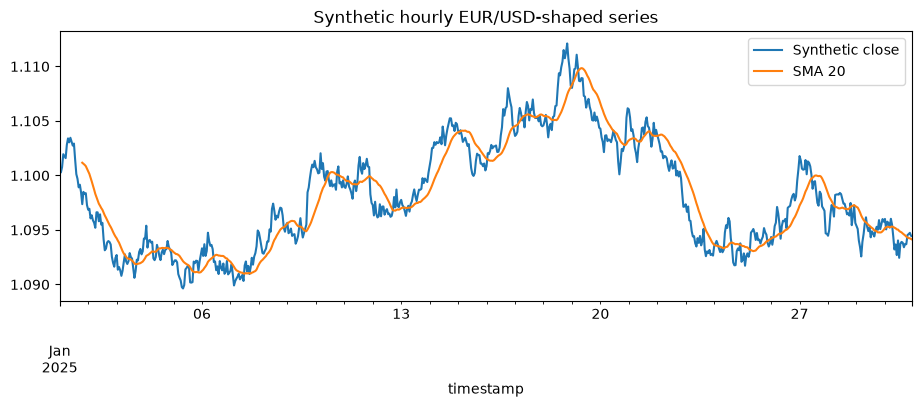

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (11, 3.5)
ax = data.Close.plot(title='Synthetic hourly EUR/USD-shaped series')
data.Close.rolling(20).mean().plot(ax=ax, label='SMA 20')
ax.legend(['Synthetic close', 'SMA 20']); plt.show()

## 3. Reject size that exceeds a risk budget
Account currency USD; units EUR; fixed per-unit execution-cost assumption. Not a broker lot calculator.

In [4]:
equity, risk_fraction = 1000, 0.0025
entry, stop, cost = 1.1000, 1.0980, 0.0002
budget = equity * risk_fraction
units = int(min(budget/(entry-stop+cost), equity/(entry+cost)))
pd.Series({'Budget USD': budget, 'Units EUR': units, 'Notional USD': units*entry,
 'Estimated loss USD': units*(entry-stop+cost)})

Budget USD              2.5000
Units EUR             908.0000
Notional USD          998.8000
Estimated loss USD      1.9976
dtype: float64

## 4. Extract an event; do not execute the text
Untrusted social content has no permission to place orders or modify risk limits.

In [5]:
event = {
 'event_id': 'SYNTHETIC-001',
 'source': 'training_example',
 'published_at': '2026-11-09T10:00:00Z',
 'received_at': '2026-11-09T10:00:08Z',
 'verified': False,
 'action': 'NO_TRADE',
 'reason': 'No primary-source confirmation'
}
pd.Series(event)

event_id                         SYNTHETIC-001
source                        training_example
published_at              2026-11-09T10:00:00Z
received_at               2026-11-09T10:00:08Z
verified                                 False
action                                NO_TRADE
reason          No primary-source confirmation
dtype: object

## 5. Inspect simulated results, not a profit promise
The HTML report is generated by Backtesting.py / Bokeh on the synthetic sample. The demonstration rule is intentionally simpler than the complete proposed strategy.

In [6]:
import json
summary = json.loads((ROOT/'examples/synthetic_summary.json').read_text())
pd.Series(summary, name='Synthetic demonstration only')

Start                2025-01-01 00:00:00+00:00
End                  2025-01-30 23:00:00+00:00
Return [%]               -0.044114023044876376
Max. Drawdown [%]         -0.06132305698679508
# Trades                                    22
Win Rate [%]                 36.36363636363637
Name: Synthetic demonstration only, dtype: str

## 6. Review the journal and next tests
Entries are simulated. Costs are assumptions; gaps, swaps and real execution need separate validation.

In [7]:
trades = pd.read_csv(ROOT/'examples/synthetic_trades.csv')
trades[['EntryTime','ExitTime','Size','EntryPrice','ExitPrice','PnL']].head(8)

,EntryTime,ExitTime,Size,EntryPrice,ExitPrice,PnL
0,2025-01-04 00:00:00+00:00,2025-01-04 07:00:00+00:00,500,1.094326,1.092217,-1.164038
1,2025-01-06 01:00:00+00:00,2025-01-06 12:00:00+00:00,500,1.093424,1.091314,-1.163903
2,2025-01-07 23:00:00+00:00,2025-01-08 12:00:00+00:00,500,1.093608,1.097499,1.835770
3,2025-01-08 13:00:00+00:00,2025-01-08 14:00:00+00:00,500,1.097526,1.095416,-1.164518
4,2025-01-09 12:00:00+00:00,2025-01-09 13:00:00+00:00,500,1.096191,1.094081,-1.164318
5,2025-01-09 18:00:00+00:00,2025-01-10 04:00:00+00:00,500,1.098557,1.102447,1.835027
6,2025-01-10 05:00:00+00:00,2025-01-10 05:00:00+00:00,500,1.102144,1.100034,-1.165211
7,2025-01-11 13:00:00+00:00,2025-01-11 22:00:00+00:00,500,1.101014,1.098904,-1.165041
